# Enterprise Data Architecture & Reconciliation

## The Scenario
You are a Senior Data Analyst at a massive FinTech company. The Data Engineering team is on vacation, and the CFO needs the Q1-Q4 Financial Audit Dashboard by Friday.

You have been given access to three separate, messy systems:
1. **The HR Database (`enterprise_database.db`):** A SQL database containing user accounts. *Warning: It contains historical logs, meaning users appear multiple times. You only want their most recent status.*
2. **The Server Logs (`server_logs.txt`):** 100,000 raw text logs. The transaction data is trapped inside strings.
3. **The Finance Server (`daily_exchange_rates.csv`):** A list of daily EUR to USD exchange rates. *Warning: The financial market is closed on weekends, so weekend dates have missing exchange rates.*

## Your Mission
You must architect a Python pipeline to extract, clean, merge, and visualize this data.

**Requirements for Passing:**
1. **Advanced SQL:** Extract only "Active" users from the database using the most recent `updated_at` timestamp.
2. **String Manipulation (Regex):** Extract the Date, User ID, Product ID, and Euro Value from the raw text logs. Filter out rows labeled "ERROR".
3. **Temporal Joins:** Join the transactions to the exchange rate table based on the exact day. You must forward-fill the weekend exchange rates so transactions don't drop out.
4. **Efficiency:** Your code must run on all 100,000 rows in under 2 minutes. No `for` loops allowed in Pandas.
5. **Dashboard:** Build visualizations showing Total USD Revenue by Month and Top 5 Most Valuable Customers.

In [7]:

# ===================================================================
# PHASE 1: SQL EXTRACTION
# ===================================================================

import sqlite3
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns

# Connect to database
conn = sqlite3.connect("enterprise_database (1).db")

# SQL: get the latest record for each user
query = """
SELECT user_id, name, status, updated_at
FROM (
    SELECT
        user_id,
        name,
        status,
        updated_at,
        ROW_NUMBER() OVER (
            PARTITION BY user_id
            ORDER BY updated_at DESC
        ) AS rn
    FROM users
)
WHERE rn = 1
AND status = 'Active';
"""

# Load latest Active users
df_active_users = pd.read_sql_query(query, conn)

# Close database connection
conn.close()

# Check result
print("Active users:", len(df_active_users))
print(df_active_users.head())

Active users: 14183
   user_id          name  status           updated_at
0  U-00001  User_U-00001  Active  2023-01-28 14:00:00
1  U-00003  User_U-00003  Active  2023-01-22 14:00:00
2  U-00005  User_U-00005  Active  2023-01-17 14:00:00
3  U-00006  User_U-00006  Active  2023-01-05 14:00:00
4  U-00007  User_U-00007  Active  2023-01-27 14:00:00


In [8]:
# ============================================================
# PHASE 2: REGEX & UNSTRUCTURED DATA WRANGLING
# ============================================================

import pandas as pd
import re

# Load the server log file
logs = pd.read_csv(
    "server_logs (1).txt",
    header=None,
    names=["raw_log"]
)

print("Total log records:", len(logs))

# ------------------------------------------------------------
# 1. Remove ERROR records
# ------------------------------------------------------------

logs_clean = logs[
    ~logs["raw_log"].str.contains("ERROR", na=False)
].copy()

print("Records after removing ERROR:", len(logs_clean))

# ------------------------------------------------------------
# 2. Extract Date
# ------------------------------------------------------------

logs_clean["Date"] = logs_clean["raw_log"].str.extract(
    r'\[(\d{4}-\d{2}-\d{2})'
)[0]

# ------------------------------------------------------------
# 3. Extract User ID
# ------------------------------------------------------------

logs_clean["User_ID"] = logs_clean["raw_log"].str.extract(
    r'"u"\s*:\s*"(U-\d+)"'
)[0]

# ------------------------------------------------------------
# 4. Extract Product ID
# ------------------------------------------------------------

logs_clean["Product_ID"] = logs_clean["raw_log"].str.extract(
    r'"item_code"\s*:\s*"(PRD-\d+)"'
)[0]

# ------------------------------------------------------------
# 5. Extract Euro Value
# ------------------------------------------------------------

logs_clean["Euro_Value"] = logs_clean["raw_log"].str.extract(
    r'"eur_val"\s*:\s*([0-9]+(?:\.[0-9]+)?)'
)[0]

# ------------------------------------------------------------
# 6. Convert data types
# ------------------------------------------------------------

logs_clean["Date"] = pd.to_datetime(
    logs_clean["Date"],
    errors="coerce"
)

logs_clean["Euro_Value"] = pd.to_numeric(
    logs_clean["Euro_Value"],
    errors="coerce"
)

# ------------------------------------------------------------
# 7. Create clean transaction dataframe
# ------------------------------------------------------------

extracted_data = logs_clean[
    ["Date", "User_ID", "Product_ID", "Euro_Value"]
].copy()

# Remove incomplete records
extracted_data = extracted_data.dropna(
    subset=["Date", "User_ID", "Product_ID", "Euro_Value"]
)

# ------------------------------------------------------------
# 8. Display results
# ------------------------------------------------------------

print("\nExtracted transaction data:")
print(extracted_data.head())

print("\nFinal extracted records:", len(extracted_data))

print("\nMissing values:")
print(extracted_data.isnull().sum())

Total log records: 100001
Records after removing ERROR: 94903

Extracted transaction data:
        Date  User_ID Product_ID  Euro_Value
1 2023-03-15  U-19484    PRD-874     3404.44
3 2023-05-09  U-18932    PRD-905     3406.21
4 2023-10-21  U-15882    PRD-284      164.08
5 2023-01-10  U-22781    PRD-665       26.80
6 2023-05-23  U-13348    PRD-589     4964.77

Final extracted records: 94902

Missing values:
Date          0
User_ID       0
Product_ID    0
Euro_Value    0
dtype: int64


In [9]:
# ============================================================
# PHASE 3: FINANCIAL RECONCILIATION & MERGING
# ============================================================

# Load exchange rates
exchange_rates = pd.read_csv(
    "daily_exchange_rates (1).csv"
)

# Convert Date
exchange_rates["Date"] = pd.to_datetime(
    exchange_rates["Date"],
    errors="coerce"
)

# Sort by Date
exchange_rates = exchange_rates.sort_values("Date")

# Forward-fill exchange rates
exchange_rates["EUR_to_USD"] = (
    exchange_rates["EUR_to_USD"].ffill()
)

print("Exchange-rate rows:", len(exchange_rates))


# ------------------------------------------------------------
# Merge transactions + exchange rates
# ------------------------------------------------------------

df_final = extracted_data.merge(
    exchange_rates,
    on="Date",
    how="left"
)

print("After exchange-rate merge:", len(df_final))


# ------------------------------------------------------------
# Merge with Active users
# ------------------------------------------------------------

df_final = df_final.merge(
    df_active_users[
        ["user_id", "name", "status", "updated_at"]
    ],
    left_on="User_ID",
    right_on="user_id",
    how="left"
)

print("After Active-user merge:", len(df_final))


# ------------------------------------------------------------
# Calculate USD Revenue
# ------------------------------------------------------------

df_final["USD_Revenue"] = (
    df_final["Euro_Value"] *
    df_final["EUR_to_USD"]
)

print("USD Revenue calculated successfully.")


# ------------------------------------------------------------
# Show final result
# ------------------------------------------------------------

print("\nFinal dataset:")
display(df_final.head())

print("\nFinal columns:")
print(df_final.columns.tolist())

Exchange-rate rows: 365
After exchange-rate merge: 94902
After Active-user merge: 94902
USD Revenue calculated successfully.

Final dataset:


,Date,User_ID,Product_ID,Euro_Value,EUR_to_USD,user_id,name,status,updated_at,USD_Revenue
0,2023-03-15,U-19484,PRD-874,3404.44,1.178232,U-19484,User_U-19484,Active,2023-01-11 14:00:00,4011.220772
1,2023-05-09,U-18932,PRD-905,3406.21,1.104983,NaN,NaN,NaN,NaN,3763.802674
2,2023-10-21,U-15882,PRD-284,164.08,1.075350,U-15882,User_U-15882,Active,2023-01-16 14:00:00,176.443420
3,2023-01-10,U-22781,PRD-665,26.80,1.127128,U-22781,User_U-22781,Active,2023-01-07 14:00:00,30.207030
4,2023-05-23,U-13348,PRD-589,4964.77,1.019626,NaN,NaN,NaN,NaN,5062.207773



Final columns:
['Date', 'User_ID', 'Product_ID', 'Euro_Value', 'EUR_to_USD', 'user_id', 'name', 'status', 'updated_at', 'USD_Revenue']


In [11]:
# ============================================================
# PHASE 4: AGGREGATION & VISUALIZATION
# ============================================================

# Create Month column
df_final["Month"] = (
    df_final["Date"]
    .dt.to_period("M")
    .astype(str)
)

# ------------------------------------------------------------
# Total USD Revenue by Month
# ------------------------------------------------------------

monthly_revenue = (
    df_final
    .groupby("Month", as_index=False)["USD_Revenue"]
    .sum()
)

print("MONTHLY USD REVENUE")
display(monthly_revenue)


# ------------------------------------------------------------
# Top 5 Most Valuable Customers
# ------------------------------------------------------------

top_customers = (
    df_final
    .groupby(
        ["User_ID", "name"],
        as_index=False
    )["USD_Revenue"]
    .sum()
    .sort_values(
        "USD_Revenue",
        ascending=False
    )
    .head(5)
)

print("\nTOP 5 MOST VALUABLE CUSTOMERS")
display(top_customers)

MONTHLY USD REVENUE


,Month,USD_Revenue
0,2023-01,2.223762e+07
1,2023-02,1.991433e+07
2,2023-03,2.192945e+07
3,2023-04,2.122658e+07
4,2023-05,2.224473e+07
5,2023-06,2.143139e+07
6,2023-07,2.220097e+07
7,2023-08,2.251517e+07
8,2023-09,2.156016e+07
9,2023-10,2.184012e+07



TOP 5 MOST VALUABLE CUSTOMERS


,User_ID,name,USD_Revenue
3613,U-06582,User_U-06582,40050.988262
12937,U-23313,User_U-23313,39555.806629
2078,U-03805,User_U-03805,39529.945085
11066,U-20018,User_U-20018,38649.965242
3553,U-06489,User_U-06489,38629.142146


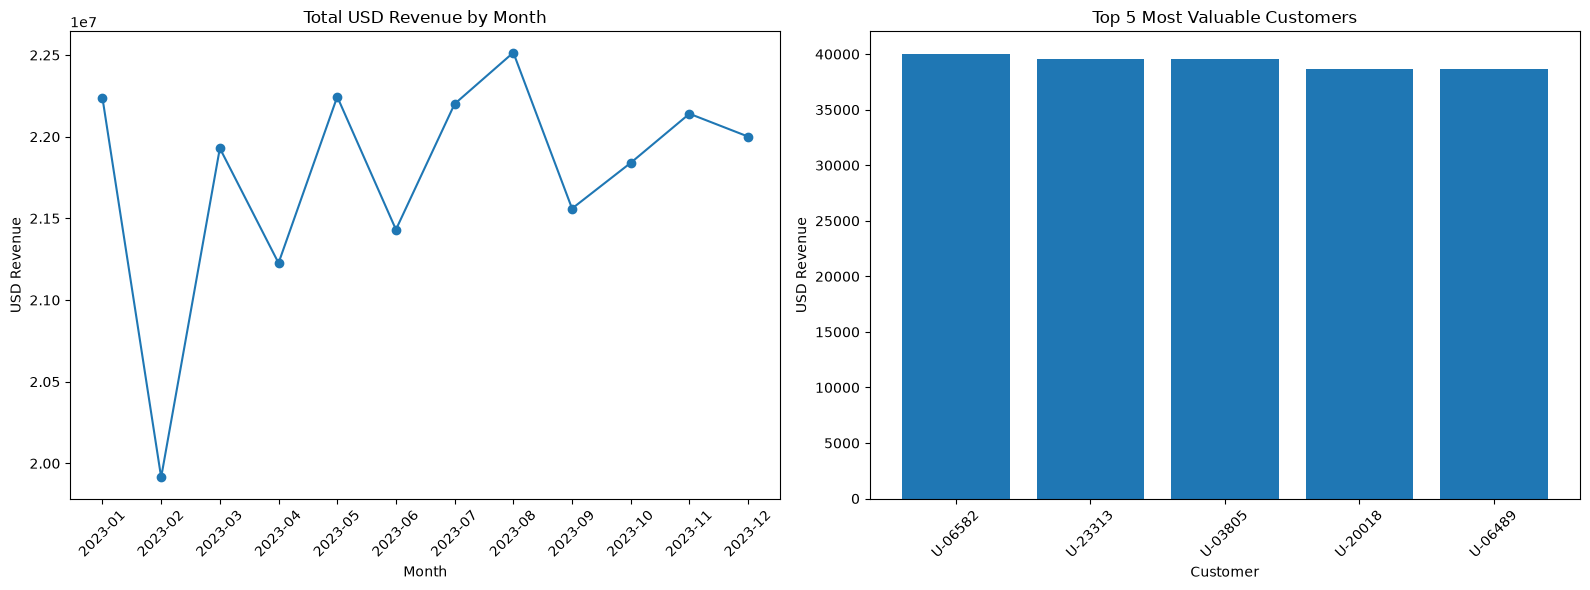

In [12]:
# ============================================================
# DASHBOARD VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

# Create dashboard
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ------------------------------------------------------------
# CHART 1: TOTAL USD REVENUE BY MONTH
# ------------------------------------------------------------

axes[0].plot(
    monthly_revenue["Month"],
    monthly_revenue["USD_Revenue"],
    marker="o"
)

axes[0].set_title("Total USD Revenue by Month")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("USD Revenue")
axes[0].tick_params(axis="x", rotation=45)

# ------------------------------------------------------------
# CHART 2: TOP 5 MOST VALUABLE CUSTOMERS
# ------------------------------------------------------------

axes[1].bar(
    top_customers["User_ID"],
    top_customers["USD_Revenue"]
)

axes[1].set_title("Top 5 Most Valuable Customers")
axes[1].set_xlabel("Customer")
axes[1].set_ylabel("USD Revenue")
axes[1].tick_params(axis="x", rotation=45)

# Display dashboard
plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# SAVE FINAL DATASET
# ============================================================

df_final.to_csv(
    "final_reconciled_data.csv",
    index=False
)

print("Final reconciled dataset saved successfully.")
print("Rows:", len(df_final))
print("Columns:", len(df_final.columns))

Final reconciled dataset saved successfully.
Rows: 94902
Columns: 11


In [14]:
# ============================================================
# FINAL PROJECT CHECK
# ============================================================

print("========== PROJECT COMPLETION CHECK ==========")

print("Active users:", len(df_active_users))
print("Valid transactions:", len(extracted_data))
print("Exchange-rate records:", len(exchange_rates))
print("Final reconciled rows:", len(df_final))

print("\nRequired columns:")
print(df_final.columns.tolist())

print("\nMissing values:")
print(df_final.isnull().sum())

print("\nProject completed successfully.")

========== PROJECT COMPLETION CHECK ==========
Active users: 14183
Valid transactions: 94902
Exchange-rate records: 365
Final reconciled rows: 94902

Required columns:
['Date', 'User_ID', 'Product_ID', 'Euro_Value', 'EUR_to_USD', 'user_id', 'name', 'status', 'updated_at', 'USD_Revenue', 'Month']

Missing values:
Date               0
User_ID            0
Product_ID         0
Euro_Value         0
EUR_to_USD         0
user_id        41003
name           41003
status         41003
updated_at     41003
USD_Revenue        0
Month              0
dtype: int64

Project completed successfully.
